In [1]:
import subprocess
import sys

COLAB = "google.colab" in sys.modules


def _install(package):
    if COLAB:
        ans = input(f"Install { package }? [y/n]:")
        if ans.lower() in ["y", "yes"]:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "--quiet", package]
            )
            print(f"{ package } installed!")


def _colab_install_missing_deps(deps):
    import importlib

    for dep in deps:
        if importlib.util.find_spec(dep) is None:
            if dep == "iris":
                dep = "scitools-iris"
            _install(dep)


deps = ["ioos_qc"]
_colab_install_missing_deps(deps)

In [2]:
import ioos_qc

print(ioos_qc.__version__)

0.1.dev812+g6f4439a2c


#   IOOS QARTOD on Glider Data, part 1
Created: 2026-10-02

Updated: 2026-11-05

During the 2026 Google Summer of Code, a project was [proposed to evaluate](https://github.com/ioos/gsoc/issues/102) the tests present in the [QARTOD glider manual](https://cdn.ioos.noaa.gov/media/2017/12/Manual-for-QC-of-Glider-Data_05_09_16.pdf), which had recently turned 10 years old. The final project was called ["Filling the gaps within the IOOS quality control schema for ocean glider data"](https://summerofcode.withgoogle.com/programs/2026/projects/bJGGUbsA) which led to a [series of investigative notebooks](https://github.com/Klankers/mau_gsoc_qartod) that did the following for tests listed within the manual:
1. Looked at the manual's description and assessed if it made sense.
2. Looked within the [IOOS QC codebase](https://github.com/ioos/ioos_qc/tree/main/ioos_qc) and assessed if it was authentic and genuine to the manual. If not, look at where the differences were and what they would do in practice.
3. Given the unknown recent activity of the manual's original authors, make additions or changes to the QARTOD toolbox to more comprehensively perform what is described in the manual.

This general procedure was done for the following tests:
1. Timing/Gap Tests
    * Impossible date
    * Data reception
    * Time gap
2. Syntax Test
3. Location Tests
    * Location test
    * Location on land test
    * Location bounds test
4. Gross Range Tests
    * Gross range
    * Percentile range
5. Pressure Test
6. Climatology Test
14. (As ordered in the manual) Density Inversion Test

This notebook series seeks to demonstrate how the tests can be used on ocean glider datasets. Unfortunately, the following tests were not assessed:

7. Spike Test
8. Rate of Change Test
9. Flat Line TEst
10. Multi-Variate Test
11. Attenuated Signal Test
12. Previous Profile Test
13. TS Curve/Space Test

As such, these tests will not be listed in this notebook series unless updated at a later date.

Experimentation during the 2026 Google Summer of Code was commonly done on gliders using the [OG1 format](https://oceangliderscommunity.github.io/OG-format-user-manual/OG_Format.html). Plots, statistics, and any other outputs from this notebook are therefore entirely intended for educational purposes and are not intended to critically reflect on the dataset being used. Note that the results and settings present in this notebook may differ from those found at other institutions.

Data for this notebook is sourced from the Voice of the Ocean Foundation's ALSEAMAR *SeaExplorer* fleet, operating in the [Skagerrak](https://en.wikipedia.org/wiki/Skagerrak) between 2021 and 2026. This region is characterized by the interaction between deep, salty water from the [North Sea](https://en.wikipedia.org/wiki/North_Sea) interacting with fresh, relatively warm outflow from the [Baltic Sea](https://en.wikipedia.org/wiki/Baltic_Sea), passing through the [Danish Straits](https://en.wikipedia.org/wiki/Danish_Straits) and [Kattegat](https://en.wikipedia.org/wiki/Kattegat). This gives a temperature profile that is normally expected (warmest water at the surface), though the salinity profile is opposite of that typical in ocean gyres or open ocean (here, fresh water is on top).

The dataset to be used is [mission #109 of SeaExplorer number 044](https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/), operating for 20 days in September 2025.

| Notebook Number | Tests |
| --------------- | ----- |
| 1 (this notebook) | Impossible date, data reception, time gap, syntax |
| 2 | Location, location on land, location bounds |
| 3 | Gross range, percentile range, climatology |
| 4 | Pressure, density inversion |

## Load the data
Starting with imports and loading the dataset.

In [3]:
#   For loading data
#   20261022: Extracting all the plotting code.
#   The plotting helpers live next to this notebook. The file name isn't a valid module name, so load it by path.
import importlib.util

import pooch
import xarray as xr

#   Contains all of our tests
from ioos_qc import qartod

spec = importlib.util.spec_from_file_location(
    "plotting_helpers", "2026-10-22-QARTOD-help-plot.py"
)
plotting_helpers = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plotting_helpers)

#   Note: The code below is used in subsequent notebooks as `plotting_helpers.get_data()`
url = "https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/"
fname = "sea044_20250905T0639_delayed.nc"
filehash = "0bce25b78fc40bd7888a76909faa60b4f6490afd44b68a7f1f56c9d7611020ab"
download = pooch.retrieve(url=f"{url}{fname}", known_hash=f"sha256:{filehash}")
ds = xr.open_dataset(download)
ds

<xarray.Dataset> Size: 245MB
Dimensions:                             (N_MEASUREMENTS: 1699082)
Coordinates:
  * N_MEASUREMENTS                      (N_MEASUREMENTS) int64 14MB 0 ... 169...
    LATITUDE                            (N_MEASUREMENTS) float64 14MB ...
    LONGITUDE                           (N_MEASUREMENTS) float64 14MB ...
    TIME                                (N_MEASUREMENTS) datetime64[ns] 14MB ...
    DEPTH                               (N_MEASUREMENTS) float64 14MB ...
Data variables: (12/31)
    AD2CP_HEADING                       (N_MEASUREMENTS) float32 7MB ...
    AD2CP_PITCH                         (N_MEASUREMENTS) float32 7MB ...
    AD2CP_ROLL                          (N_MEASUREMENTS) float32 7MB ...
    BBP700                              (N_MEASUREMENTS) float32 7MB ...
    CHLA                                (N_MEASUREMENTS) float32 7MB ...
    DIVE_NUMBER                         (N_MEASUREMENTS) int64 14MB ...
    ...                                  ...
    SENSOR_CURRENT_PROFILERS_105527     float64 8B ...
    SENSOR_DISSOLVED_GAS_SENSORS_0095   float64 8B ...
    SENSOR_FLUOROMETERS_235280          float64 8B ...
    SENSOR_MICROSTRUCTURE_SENSORS_0496  float64 8B ...
    PROFILE_NUMBER                      (N_MEASUREMENTS) int64 14MB ...
    PROFILE_DIRECTION                   (N_MEASUREMENTS) int64 14MB ...
Attributes: (12/67)
    Conventions:                                CF-1.10, OG-1.0, Unidata Data...
    acknowledgement:                            This study used data collecte...
    agency:                                     Voice of the Ocean
    agency_role:                                contact point
    agency_role_vocabulary:                     http://vocab.nerc.ac.uk/colle...
    cdm_data_type:                              Trajectory
    ...                                         ...
    start_date:                                 20250905T0639
    basin:                                      Skagerrak
    total_dives:                                616
    dataset_id:                                 delayed_SEA044_M109
    data_url:                                   https://erddap.observations.v...
    variables:                                  ['AD2CP_HEADING', 'AD2CP_PITC...

## A note on flags
A quick disclaimer that all flags in this notebook adhere to a set defined in the QARTOD data flags manual (not just the glider manual) and [UNESCO 2013](https://www.ioccp.org/images/D4standards/IOC-OceanDataStandards54-3-2013.pdf). There are 5 flags described:

| Flag | Meaning | Definition |
|------|---------|------------|
| 1 | GOOD | Passed documented required QC tests |
| 2 | UNKNOWN (not evaluated) | Used for data when no QC test performed or the information on quality is not available |
| 3 | SUSPECT | Failed non‐critical documented metric or subjective test(s) |
| 4 | FAIL | Failed critical documented QC test(s) or as assigned by the data provider |
| 9 | MISSING | Used as place holder when data are missing |

Note that these flags differ from those used at other institutions (Argo, for example, has flag=0 for UNKNOWN).

QARTOD keeps these flags within the `qartod.QartodFlags` object for use anywhere in the package.

In [4]:
from ioos_qc.qartod import QartodFlags  #   These are stored in a Class in qartod

print(list(item for item in dir(QartodFlags) if not item.startswith("_")))
print(f"Unknown flag = {QartodFlags.UNKNOWN}")

#   Each flag is tied to a label and a color in the plotting helpers.
flag_style = plotting_helpers.flag_style

['FAIL', 'GOOD', 'MISSING', 'SUSPECT', 'UNKNOWN']
Unknown flag = 2


QARTOD flags by cascading flags onto one another by increasing severity.
* Flags are initialized as untested or `UNKNOWN` (flag 2)
* During a test, they are assigned a `GOOD` flag (1)
* In the event something goes wrong, this `GOOD` flag is overwritten:
    * Missing data are flagged as `MISSING` (9) and are not overwritten further
    * Questionable data are flagged as `SUSPECT` (3)
    * Data that are bad or fail the test are flagged as `FAIL` (4), potentially overwriting `SUSPECT` flags as well as `UNKNOWN` and `GOOD`.

In [5]:
#   The order of flags by severity
order = plotting_helpers.order
print(order)

[2, 1, 9, 3, 4]


## Preliminary data check

Begin by examining the data. It is loaded and a series of helper functions reside in `plotting_helpers.py` for visualizations in this notebook series.

Using `gsw`, some core oceanographic variables can be derived for further use in the notebook series. `gsw` uses the TEOS-10 algorithms.
* PRES - glider's reading of pressure, usually used to derive `DEPTH`.
* TEMP - seawater temperature.
* PSAL - practical salinity from conductivity.
* SA - absolute salinity from practical salinity.
* CT - conservative temperature, coming from absolute salinity and the original temperature
* SIGMA0 - or $\sigma_\theta$, typically described as the potential density referenced to the surface.



In [6]:
import gsw
import numpy as np

ds["PSAL"] = gsw.SP_from_C(ds.CNDC, ds.TEMP, ds.PRES)
ds["SA"] = gsw.SA_from_SP(ds.PSAL, ds.PRES, ds.LONGITUDE, ds.LATITUDE)
ds["CT"] = gsw.CT_from_t(ds.SA, ds.TEMP, ds.PRES)
ds["SIGMA0"] = gsw.sigma0(ds.SA, ds.CT)

time = ds.TIME.values
pres = ds.PRES.values
temp = ds.TEMP.values
psal = ds.PSAL.values
sigma0 = ds.SIGMA0.values

Furthermore, it is helpful to know some engineering information about the glider.
* PROFILE_NUMBER - a running tally of each time the glider goes up and down
* PROFILE_DIRECTION - whether the glider thinks it is ascending or decreasing

In [7]:
profile = ds.PROFILE_NUMBER.values
direction = ds.PROFILE_DIRECTION.values  # 1 = descending, -1 = ascending

print(f"{time.size} measurements in {np.unique(profile).size} profiles")
print(
    f"{np.datetime_as_string(time[0], unit='m')} to {np.datetime_as_string(time[-1], unit='m')}"
)

1699082 measurements in 1232 profiles
2025-09-05T06:39 to 2025-09-25T09:24


It is helpful to visualize the glider's oeprating area from a geospatial perspective. Data profile timeseries can be informative to identifying problems, though observations using latitude and longitude can provide additional context.

In the `location_on_land` test, this is done using the package `roaring_landmask` for high-resolution coastlines.

In [8]:
extent = (8.8, 11.6, 57.4, 59.2)  # lon_min, lon_max, lat_min, lat_max

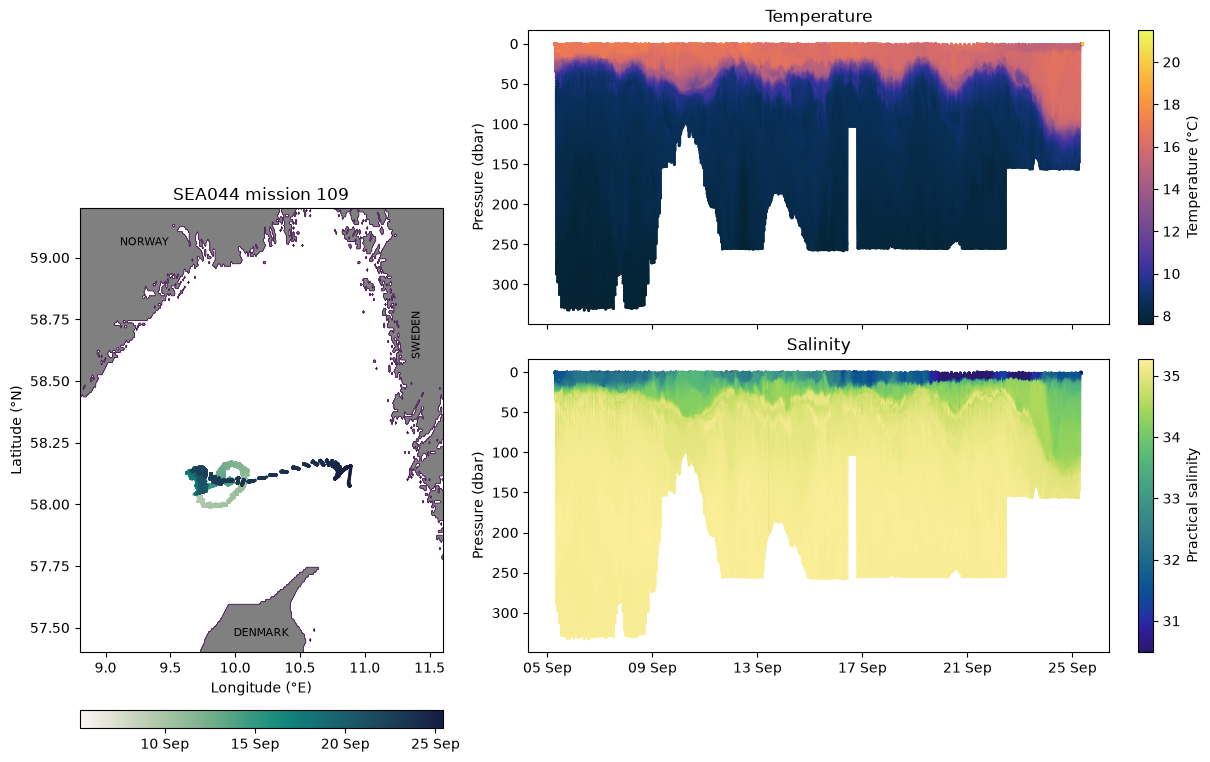

In [9]:
fig, axs = plotting_helpers.overview_figure(
    ds.LONGITUDE.values, ds.LATITUDE.values, time, pres, temp, psal, extent
)

This shows that the glider started up and did a loop, before transitioning closer to Sweden.

## Timing/Gap Tests
Prior to GSoC 2026, tests related to the `TIME` variable did not exist. Gliders do not provide a data stream as they cannot communicate while underwater. Instead, they bundle the most recent data and communicate that over satellite. This makes `TIME` tricky to work with, especially when thinking of it as a coordinate.

1. Impossible dates. I.e., something that will check the `TIME` coordinate or variable and ensure that it adheres to a "reasonable" round, like how the manual describes it.
  * Data is either present or in the past.
  * Month, day, hour, minute are all possible (Numpy `datetime64` does not tolerate impossible values)
  * Include user-specified tolerances. If the glider was deployed last week, a datetime from 4 years ago should be out of range.
2. Data reception. The manual describes a `TIM_INC` increment to flag data by if they're older than that tolerance. This test is potentially more handy for data centers, as they are *expecting* data at certain intervals. For example, one could have a glider that is returning reasonable datetimes, they're just not coming in as recent as specified.
3. Time gaps. Though this test cannot run in real-time, glider temporal data gaps can be identified by checking the `TIME` variable against an expected period.

### Impossible Dates
This test runs with an optional argument with a `fail_span`, used to designate a user-defined window of times where data can be potentially bad.

To demonstrate this, some fake data will be injected with a defined `fail_span`.
* A time in the future (not possible).
* An extremely old, but possible point.
* A point prior to the specified deployment, but much closer than the bullet above.
* A missing point, or NaT.

In [10]:
time_bad = time.copy()
injected = {
    200000: np.datetime64("2031-02-14T12:00:00"),  #    in the future
    600000: np.datetime64("1970-01-01T00:00:00"),  #    Unix epoch
    900000: np.datetime64("2025-08-15T00:00:00"),  #    before the deployment
    1200000: np.datetime64("NaT", "ns"),  # missing
}
for i, t in injected.items():
    time_bad[i] = t

deployed = ds.DEPLOYMENT_TIME.values
window = (
    deployed,
    deployed + np.timedelta64(30, "D"),
)  #   Let's say we add 30 days or so from the beginning of the deployment.

flags_date = qartod.impossible_date_test(time_bad)
flags_date_window = qartod.impossible_date_test(time_bad, fail_span=window)

plotting_helpers.flag_counts(
    flags_date, "No window:"
)  #   This is a helper function that prints out the number of flags of each type, formatted
plotting_helpers.flag_counts(flags_date_window, "Deployment window:")

No window:                  GOOD=1,699,080, MISSING=1, FAIL=1
Deployment window:          GOOD=1,699,078, MISSING=1, FAIL=3


Only one data point fails without using the `fail_span`, since the default `impossible_date_test` is only looking for values that can't logically happen (improperly formatted or values in the future). The only point that fails is the value from 2031, whereas adding the defined deployment window further constrains what is acceptable.

The `MISSING` flag is denoted as a grey "X" on X-axis of the plots below.

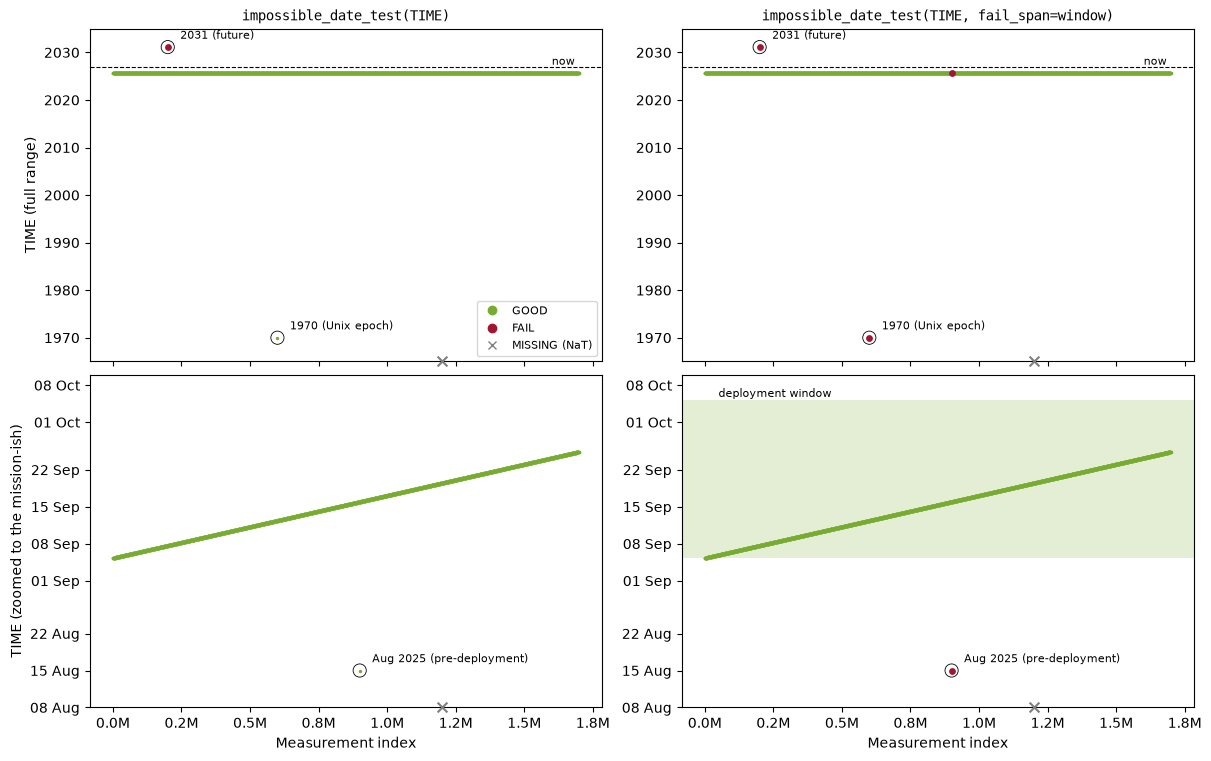

In [11]:
labels = {
    200000: "2031 (future)",
    600000: "1970 (Unix epoch)",
    900000: "Aug 2025 (pre-deployment)",
}
fig, axs = plotting_helpers.impossible_date_figure(
    time_bad, flags_date, flags_date_window, window, injected, labels
)

### Data Reception
The data reception test originated from a potential use for data centers. To demonstrate the test, this notebook will assume a scenario where the check happens 10 days into the mission (`from_time`):
* data more than 48 h older than `from_time` is stale, so **FAIL**,
* data within 48 h of `from_time` is **GOOD**,
* data *newer* than `from_time` is not judged by this test and passes through as **GOOD**.

With the default `from_time` (now), every point in a 2025 dataset is stale.

*Note: This test may not be appropriate for delayed-mode or archived datasets unless the `from_time` is explicitly specified.*

In [12]:
check_time = time[0] + np.timedelta64(
    10, "D"
)  #   Need to assign based on time[0] plus some offset
max_age_hours = 48

flags_rx = qartod.data_reception_test(
    time, fail_span=max_age_hours, from_time=check_time
)
plotting_helpers.flag_counts(
    flags_rx, f"from_time = {np.datetime_as_string(check_time, unit='h')}:"
)
plotting_helpers.flag_counts(
    qartod.data_reception_test(time, fail_span=max_age_hours), "from_time = now:"
)

from_time = 2025-09-15T06:  GOOD=1,023,164, FAIL=675,918
from_time = now:            FAIL=1,699,082


The mission is longer than 10 days, so when the `from_time` argument is specified, not all of the data fail.

In the plots below, we can see exactly where the default "stale" data are (`max_age_hours`) from the `from_time` date provided.

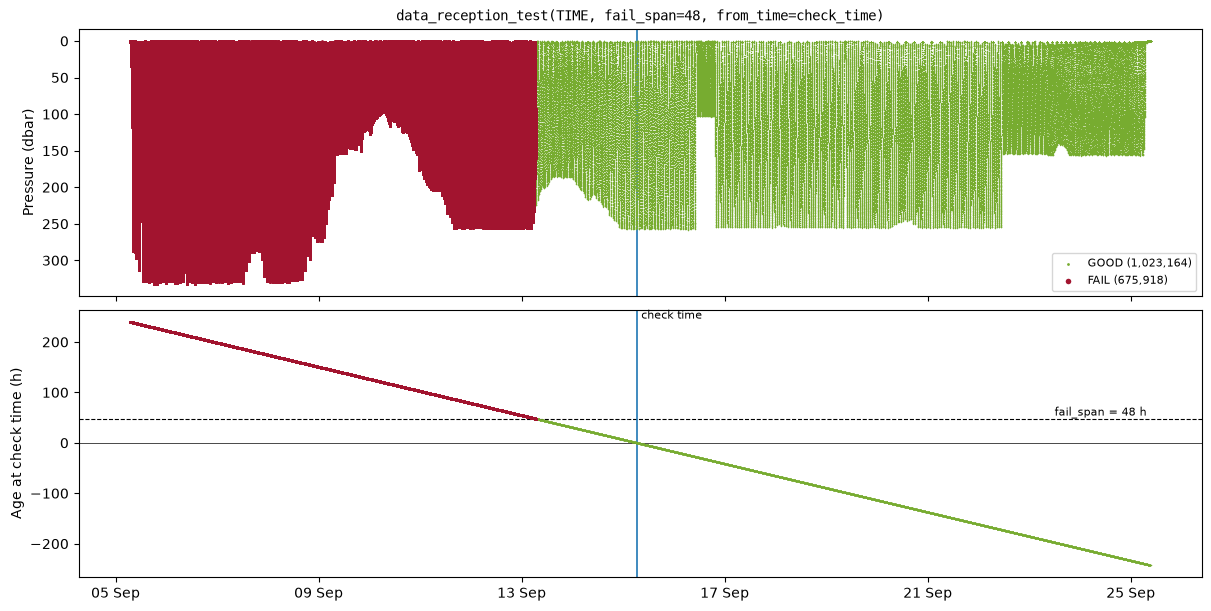

In [13]:
fig, axs = plotting_helpers.data_reception_figure(
    time, pres, flags_rx, check_time, max_age_hours
)

### Time Gaps
Next comes the assessment of data gaps within the data, which is appropriate for archived or delayed-mode glider datasets. The test looks at the difference in the `TIME` variable for each iterative measurement and flags points that exceed a tolerance.

In [14]:
dt_seconds = np.diff(time) / np.timedelta64(1, "s")
print(
    f"Median step: {np.median(dt_seconds)} s, longest: {dt_seconds.max()} s, zero-length (duplicates): {np.count_nonzero(dt_seconds == 0)}"
)

Median step: 1.0 s, longest: 125.0 s, zero-length (duplicates): 4500


In the data loaded here, most data points are spaced at about a second apart. However, there are some real gaps that can arise. The longest is 125 seconds.

In [15]:
plotting_helpers.flag_counts(qartod.time_gap_test(time), "fail_span = 2 h:")
plotting_helpers.flag_counts(
    qartod.time_gap_test(time, fail_span=1 / 60), "fail_span = 1 min:"
)

fail_span = 2 h:            GOOD=1,699,082
fail_span = 1 min:          GOOD=1,699,072, FAIL=10


There are only a few points that are a minute or longer. The point that *follows* the gap is what is flagged.

To see a real gap, this notebook will simulate a data dropout by deleting six hours of measurements from the middle of the mission, as might happen if a data file was lost. Then the test is run with the default 2 h `fail_span`.

In [16]:
gap_start = np.datetime64("2025-09-15T06:00")
gap_end = gap_start + np.timedelta64(6, "h")
keep = (time < gap_start) | (time >= gap_end)

time_gappy = time[keep]
pres_gappy = pres[keep]
flags_gap = qartod.time_gap_test(time_gappy, fail_span=2)
plotting_helpers.flag_counts(flags_gap, "Simulated dropout:")
print(
    "Flagged point:",
    np.datetime_as_string(
        time_gappy[np.ma.getdata(flags_gap) == QartodFlags.FAIL][0], unit="s"
    ),
)

Simulated dropout:          GOOD=1,677,961, FAIL=1
Flagged point: 2025-09-15T12:00:00


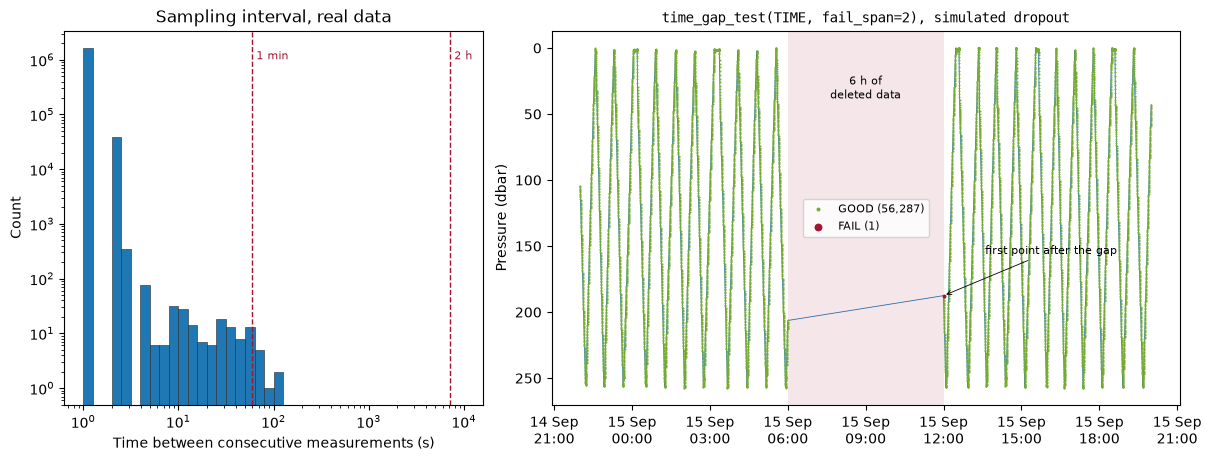

In [17]:
fig, axs = plotting_helpers.time_gap_figure(
    dt_seconds, time_gappy, pres_gappy, flags_gap, gap_start, gap_end
)

## Syntax Test
The syntax test has been implemented within QARTOD to be more generic for some of the raw messages that a glider can transmit.

The syntax test works on the **raw messages** a glider sends, before they are parsed into numbers. Common among these is HEX or hexadecimal format, which can then be parsed into bytes.
> CF010502AF02470085010101169217199E9401AD85091F48979B004662240E - an example HEX string from Argo.

So there are multiple ways that the data could be parsed - it could be a HEX-encoded string like above, or a more conventional list of characters, perhaps with a delimiter (like glider NMEA strings).

Each message is checked for having the expected length, measured in one of three ways:
* `lentype="char"`: number of characters,
* `lentype="byte"`: number of bytes in a HEX-encoded string (two characters per byte),
* `delimiter=";"`: number of fields once the message is split on a delimiter. This is used in combination with `lentype="char"`.

To simulate this test, this notebook will rebuild some semicolon-delimited records with time, state, pressure, T, and C to test the `char` argument.

Then, these records will be "damaged":
* Truncation - when data gets cut off
* Dropping a field - like if for whatever reason a sensor goes offline
* Stray char - when something isn't collapsed correctly in the raw data or some static noise is introduced through a bad config
* Records merged - very common on CTDs when writing to a physical disk too slowly, missing the newline

In [18]:
ix = 500000
n_meas = 40
sub = slice(ix, ix + n_meas)
records = []
for t, nav, p, tc, c in zip(
    time[sub],
    ds.NAV_RESOURCE.values[sub],
    pres[sub],
    temp[sub],
    ds.CNDC.values[sub],
    strict=True,
):
    records.append(
        f"{np.datetime_as_string(t, unit='ms')};"
        f"{nav:03.0f};{p:08.3f};{tc:07.4f};{c:07.4f}"
    )
good_len = len(records[0])
good_field = len(records[0].split(";"))
print(f"{len(records)} items: {records}")
print(f"Good length = {good_len} characters. Good field length = {good_field}")

40 items: ['2025-09-11T04:41:49.000;118;0200.145;08.0313;36.5509', '2025-09-11T04:41:50.000;118;0200.207;08.0303;36.5479', '2025-09-11T04:41:51.000;118;0200.258;08.0287;36.5464', '2025-09-11T04:41:52.000;118;0200.299;08.0273;36.5465', '2025-09-11T04:41:53.000;118;0200.321;08.0273;36.5486', '2025-09-11T04:41:54.000;118;0200.331;08.0254;36.5453', '2025-09-11T04:41:55.000;118;0200.331;08.0254;36.5457', '2025-09-11T04:41:56.000;118;0200.312;08.0239;36.5448', '2025-09-11T04:41:57.000;118;0200.274;08.0239;36.5457', '2025-09-11T04:41:58.000;118;0200.230;08.0233;36.5467', '2025-09-11T04:41:59.000;118;0200.176;08.0233;36.5461', '2025-09-11T04:42:00.000;118;0200.105;08.0240;36.5458', '2025-09-11T04:42:01.000;118;0200.024;08.0241;36.5453', '2025-09-11T04:42:02.000;118;0199.927;08.0235;36.5458', '2025-09-11T04:42:03.000;118;0199.826;08.0236;36.5459', '2025-09-11T04:42:04.000;118;0199.706;08.0238;36.5459', '2025-09-11T04:42:05.000;118;0199.579;08.0237;36.5461', '2025-09-11T04:42:06.000;118;0199.438

A good record is 52 characters long, with 5 fields.

In [ ]:
print("These are the damaged lines:")
print(f"Nothing wrong:      {records[0]}")
#   By index to transform the line
damage = {
    6: ("truncated", lambda r: r[:-3]),  # transmission cut off
    15: ("field dropped", lambda r: ";".join(r.split(";")[:3] + r.split(";")[4:])),
    24: ("stray character", lambda r: r[:30] + "#" + r[30:]),
    33: ("records merged", lambda r: r + records[34]),
}
for i, (what, fn) in damage.items():
    records[i] = fn(records[i])
    print(f"{i:>2d} {what:<16s} {records[i]}")
records = np.array(records)

And these are the damaged guys:
Nothing wrong:      2025-09-11T04:41:49.000;118;0200.145;08.0313;36.5509
 6 truncated        2025-09-11T04:41:55.000;118;0200.331;08.0254;36.5
15 field dropped    2025-09-11T04:42:04.000;118;0199.706;36.5459
24 stray character  2025-09-11T04:42:13.000;118;01#98.307;08.0246;36.5467
33 records merged   2025-09-11T04:42:22.000;118;0196.500;08.0314;36.55432025-09-11T04:42:23.000;118;0196.299;08.0352;36.5582


This can run two ways: By **counting characters** or delimited **fields**.

In [20]:
flags_char = qartod.syntax_test(records, nchar=good_len, lentype="char")
flags_field = qartod.syntax_test(records, nchar=good_field, delimiter=";")
plotting_helpers.flag_counts(flags_char, "By characters:")
plotting_helpers.flag_counts(flags_field, "By fields:")

By characters:              GOOD=36, FAIL=4
By fields:                  GOOD=38, FAIL=2


The two methods catch different problems:
* **Counting characters** catches all four, but only because we used a fixed-width format. If the numbers were written with variable width (e.g. `9.87` vs `10.12`), healthy records would differ in length and fail too.
* **Counting fields** is robust to variable-width numbers, but it misses the truncated record (the cut-off is inside the last field, so there are still 5 fields) and the stray character (no extra `;`).

So each has limitations.

When it comes to `lentype="byte"`, each HEX byte itself is two characters. So strings of odd lengths will fail right away.

In [21]:
hex_records = np.array(
    [
        "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B7371",  # 37 bytes
        "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B737",  # odd length
        "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B73",  # 36 bytes
    ]
)
print(qartod.syntax_test(hex_records, nchar=37, lentype="byte"))

[1 4 4]


The first line was successful because it satisftied the `nchar` "byte-type" `lentype`, the second line failed because it is an odd length, and the third line was too short (36 < 37).

The bars below visualize the results as by their length. The number of characters, and the number of fields, can change the length overall expected length.

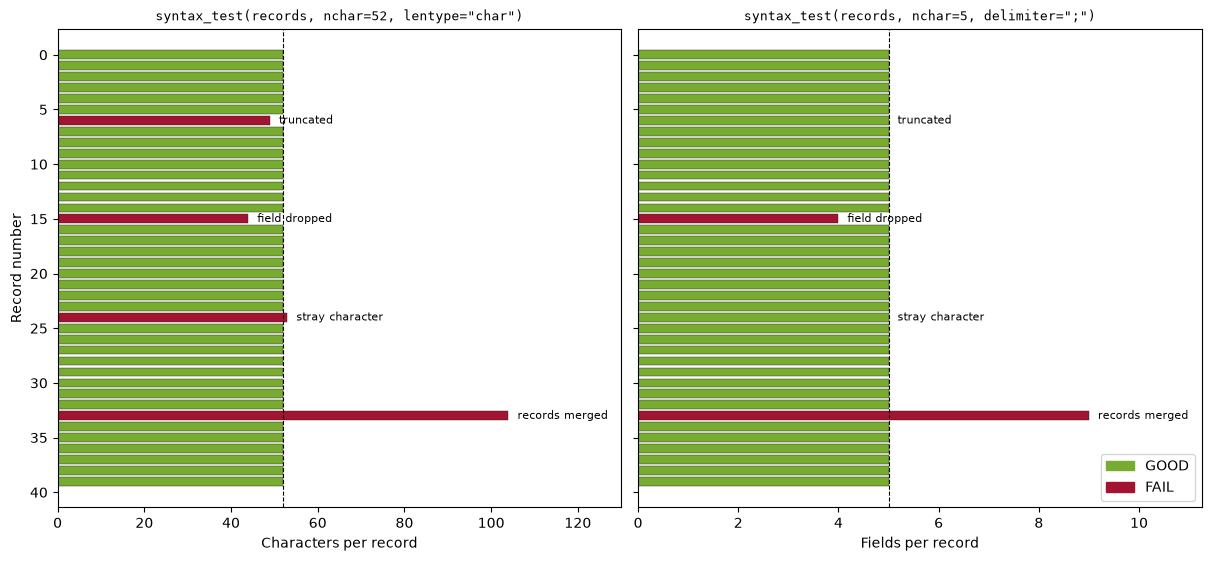

In [22]:
fig, axs = plotting_helpers.syntax_figure(
    records, flags_char, flags_field, good_len, good_field, damage
)

This notebook is continued in part 2, which covers the Location Tests.